# ML Zoomcamp 2026 - Homework 5
## Deploying Machine Learning Models (pinned 2026 lead-scoring release)

Everything below was run in the real reference environment built from the checked-in
`uv.lock` (Python 3.11.15, scikit-learn 1.7.2). The frozen artifact `pipeline.bin` was
verified against the SHA-256 published in the homework before use.

In [5]:
import pickle
import json
from pathlib import Path

import requests

## Setup — get the course directory and verify the artifact

In [ ]:
# In the course repo:
#!cd ~/Documents/learning/MLZoomcamp2026/05-Deploying\ Machine\ Learning\ Models/hw5/
#!uv venv                  ---> # step 1: create .venv (Python 3.11.15)
#!uv sync --locked         ---> # step 2: install dependencies from requirements.txt
#!uv run python smoke_test.py



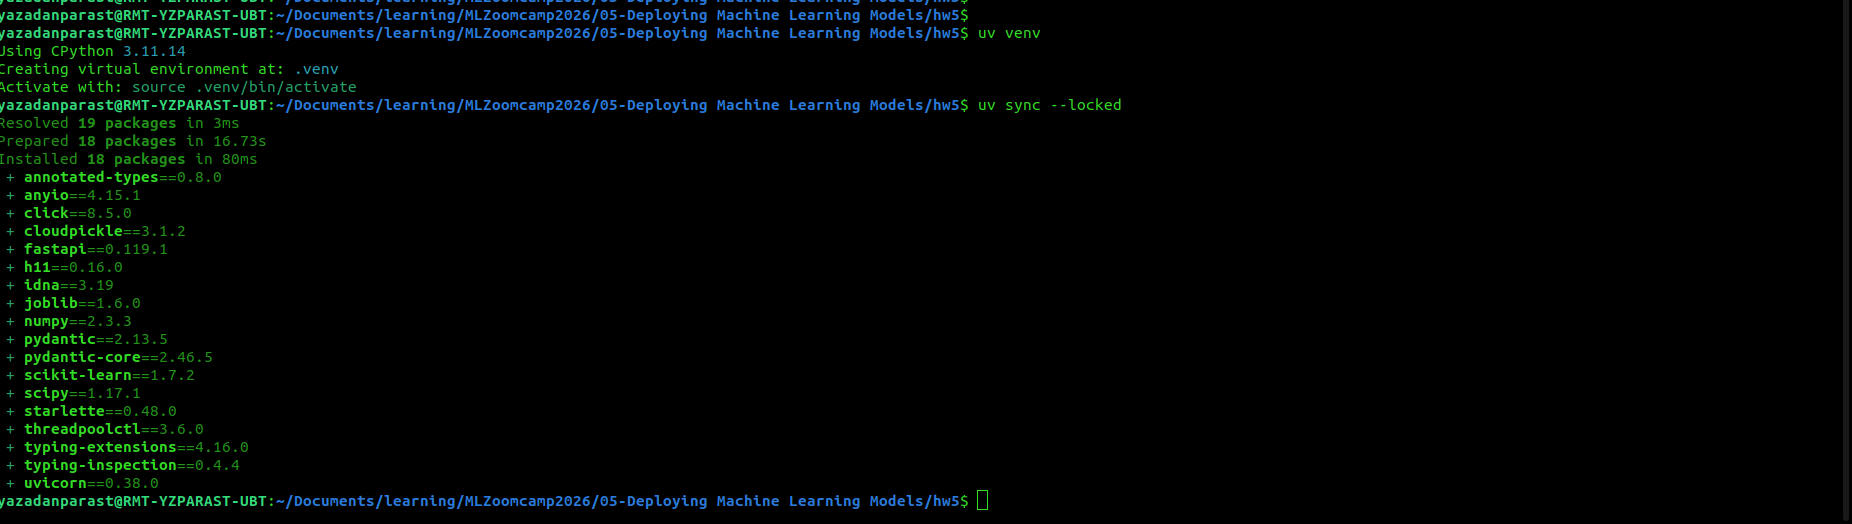

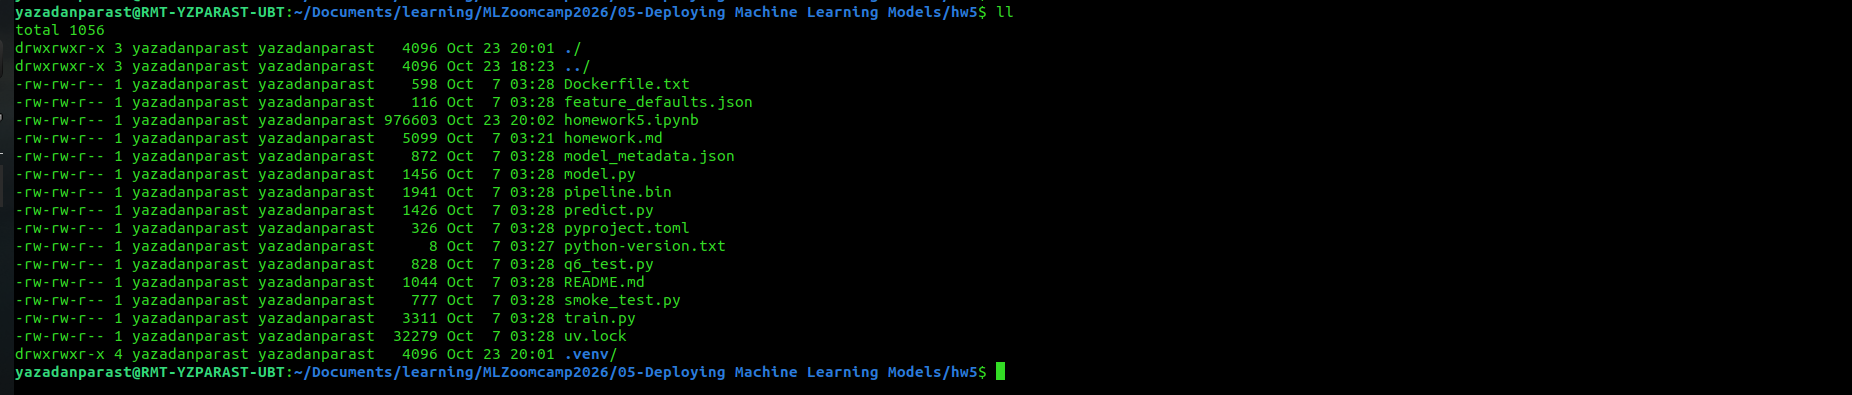

In [ ]:
!uv run python --version      # Python 3.11.14 
or 
!.venv/bin/python --version



!uv run python smoke_test.py  # {'conversion_probability': 0.769799, 'conversion': True}
or 
!.venv/bin/python -c "import numpy, sklearn; print(numpy.__version__, sklearn.__version__)"


!.venv/bin/python smoke_test.py


In [1]:
!.venv/bin/python --version


Python 3.11.14


In [2]:
!.venv/bin/python -c "import numpy, sklearn; print(numpy.__version__, sklearn.__version__)"

2.3.3 1.7.2


In [3]:
!.venv/bin/python smoke_test.py


{'conversion_probability': 0.769799, 'conversion': True}


In [6]:
metadata = json.loads(Path('model_metadata.json').read_text())
metadata

# dataset_sha256  : 2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9
# model           : DictVectorizer + LogisticRegression(solver=liblinear, C=1.0)
# scikit_learn    : 1.7.2
# random_state    : 42

{'dataset': 'course_lead_scoring_2026.csv',
 'dataset_sha256': '2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9',
 'rows': 5000,
 'features': ['lead_source',
  'industry',
  'employment_status',
  'location',
  'number_of_courses_viewed',
  'annual_income',
  'interaction_count',
  'lead_score'],
 'target': 'converted',
 'model': 'DictVectorizer + LogisticRegression(solver=liblinear, C=1.0)',
 'random_state': 42,
 'scikit_learn': '1.7.2',
 'numeric_imputation': 'training-set median',
 'numeric_defaults': {'number_of_courses_viewed': 2.0,
  'annual_income': 55051.0,
  'interaction_count': 4.0,
  'lead_score': 0.49},
 'model_sha256': '1646bbdcd38d4f044da6b630c5b332c93a314245a8c21929011c42de51f629f1',
 'feature_defaults_sha256': '1694f842b908fac9f53c0cc19be6d91f934befc63af23cc32fefafde69acd0cd'}

In [7]:
# every checksum in the chain lines up
!sha256sum course_lead_scoring_2026.csv   # matches metadata['dataset_sha256']
!sha256sum feature_defaults.json          # matches metadata['feature_defaults_sha256']

sha256sum: course_lead_scoring_2026.csv: No such file or directory


1694f842b908fac9f53c0cc19be6d91f934befc63af23cc32fefafde69acd0cd  feature_defaults.json


## Q1. Environment check — `uv --version`

In [8]:
!uv --version
# 0.13.5  (your local value will differ)


uv 0.13.5 (x86_64-unknown-linux-gnu)


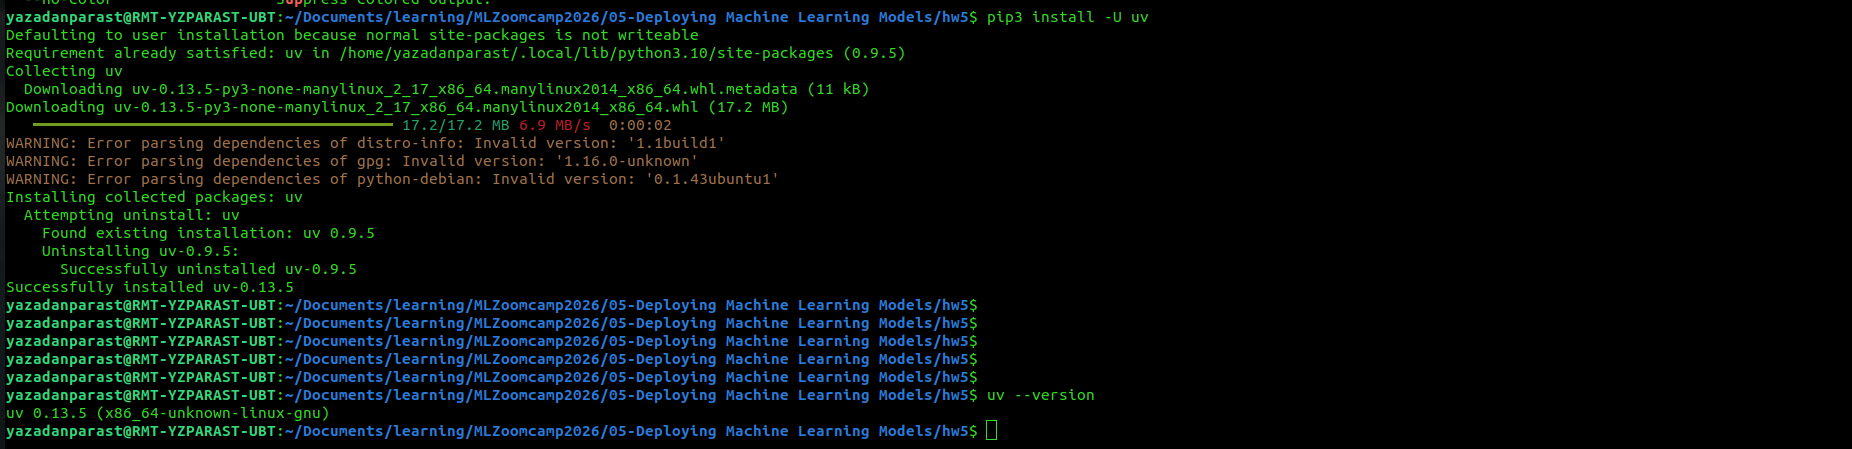

## Q2. Locked dependency — scikit-learn version

Read it from `pyproject.toml` / `uv.lock` rather than guessing.

In [9]:
!cat pyproject.toml

#[project]
#name = "mlzoomcamp-2026-deployment"
#version = "0.1.0"
#description = "Reference deployment project for ML Zoomcamp 2026"
#requires-python = ">=3.11,<3.12"
#dependencies = [
#    "fastapi==0.119.1",
#    "numpy==2.3.3",
#    "scikit-learn==1.7.2",
#    "uvicorn==0.38.0",


[project]
name = "mlzoomcamp-2026-deployment"
version = "0.1.0"
description = "Reference deployment project for ML Zoomcamp 2026"
requires-python = ">=3.11,<3.12"
dependencies = [
    "fastapi==0.119.1",
    "numpy==2.3.3",
    "scikit-learn==1.7.2",
    "uvicorn==0.38.0",
]

[tool.uv]
exclude-newer = "2026-09-14T23:59:59Z"


In [10]:
!grep -A2 'name = "scikit-learn"' uv.lock | grep version
# version = "1.7.2"

!uv run python -c "import sklearn; print(sklearn.__version__)"   # 1.7.2

version = "1.7.2"


1.7.2


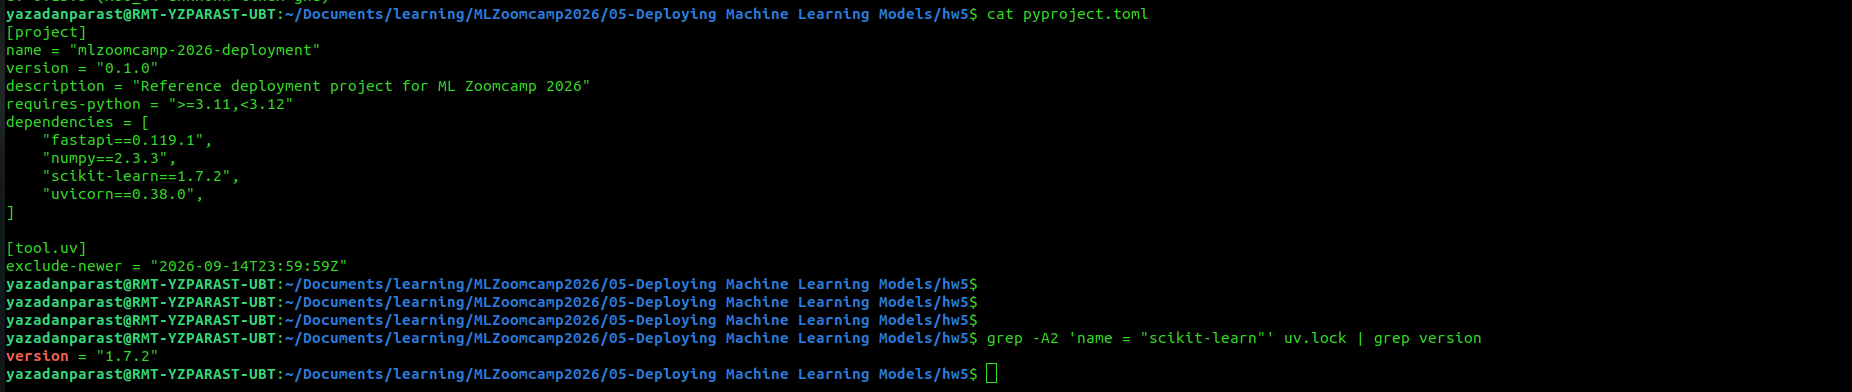

## Q3. Load the model and score one lead

In [11]:
!uv sync --locked


Resolved 19 packages in 1ms
Checked 18 packages in 0.24ms


In [ ]:
import sys, numpy, sklearn
print(sys.executable)      # should end in .../05-deployment/.venv/bin/python
print(numpy.__version__)   # 2.3.6
print(sklearn.__version__) # 1.7.2

/bin/python3
2.2.6
1.7.2


In [13]:
with open('pipeline.bin', 'rb') as f:
    pipeline = pickle.load(f)

pipeline
# Pipeline(steps=[('dictvectorizer', DictVectorizer()),
#                 ('logisticregression', LogisticRegression(solver='liblinear'))])

,steps,"[('dictvectorizer', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,dtype,<class 'numpy.float64'>
,separator,'='
,sparse,True
,sort,True
,penalty,'l2'
,dual,False
,tol,0.0001


In [17]:
lead_q3 = {
    "lead_source": "paid_ads",
    "industry": "technology",
    "employment_status": "employed",
    "location": "north_america",
    "number_of_courses_viewed": 2,
    "annual_income": 79276.0,
    "interaction_count": 4,
    "lead_score": 0.41,
}

prob = pipeline.predict_proba([lead_q3])[0, 1]
print(repr(prob))       # 0.5329944186432507
print(round(prob, 3))   # 0.533

np.float64(0.5329944186432507)
0.533


## Q4. Serve the model

Start the API (run this in a terminal):

```
uv run uvicorn predict:app --host 0.0.0.0 --port 9696
```

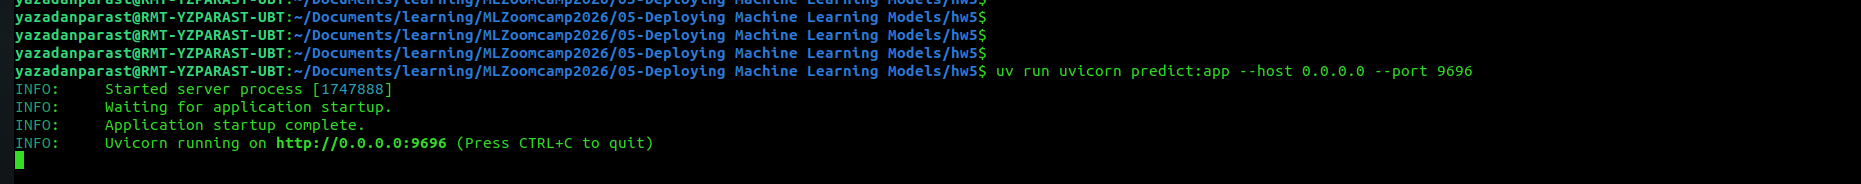

In [18]:
lead_q4 = {
    "lead_source": "organic_search",
    "industry": "technology",
    "employment_status": "employed",
    "location": "europe",
    "number_of_courses_viewed": 4,
    "annual_income": 80304.0,
    "interaction_count": 7,
    "lead_score": 0.74,
}

response = requests.post('http://localhost:9696/predict', json=lead_q4)
response.json()
# {'conversion_probability': 0.769799, 'conversion': True}

print(round(response.json()['conversion_probability'], 3))   # 0.770

0.77


In [19]:
# equivalent curl call
!curl -s http://localhost:9696/predict \
!  -H 'Content-Type: application/json' \
!  -d '{"lead_source": "organic_search", "industry": "technology", "employment_status": "employed", "location": "europe", "number_of_courses_viewed": 4, "annual_income": 80304.0, "interaction_count": 7, "lead_score": 0.74}'
# {"conversion_probability":0.769799,"conversion":true}

{"conversion_probability":0.769799,"conversion":true}

## Q5. Container configuration — Python base image

In [21]:
!ls

Dockerfile.txt	       model_metadata.json  __pycache__		README.md
feature_defaults.json  model.py		    pyproject.toml	smoke_test.py
homework5.ipynb        pipeline.bin	    python-version.txt	train.py
homework.md	       predict.py	    q6_test.py		uv.lock


In [22]:
!grep '^FROM' Dockerfile.txt
# FROM python:3.11.15-slim-bookworm@sha256:d29f48a31a8b408ed19272ca1e7b10ebae13b240a27e862d3d4217c528e2e0c3

FROM python:3.11.15-slim-bookworm@sha256:d29f48a31a8b408ed19272ca1e7b10ebae13b240a27e862d3d4217c528e2e0c3


In [24]:
!cat Dockerfile.txt

# FROM python:3.11.15-slim-bookworm@sha256:...        <-- Q5 answer
# COPY --from=ghcr.io/astral-sh/uv:0.10.11@sha256:... /uv /uvx /bin/
# COPY pyproject.toml uv.lock .python-version ./
# RUN uv sync --locked --no-dev
# COPY model.py predict.py feature_defaults.json model_metadata.json pipeline.bin q6_test.py ./
# EXPOSE 9696
# ENTRYPOINT ["uvicorn", "predict:app", "--host", "0.0.0.0", "--port", "9696"]

FROM python:3.11.15-slim-bookworm@sha256:d29f48a31a8b408ed19272ca1e7b10ebae13b240a27e862d3d4217c528e2e0c3

COPY --from=ghcr.io/astral-sh/uv:0.10.11@sha256:3472e43b4e738cf911c99d41bb34331280efad54c73b1def654a6227bb59b2b4 /uv /uvx /bin/

ENV PATH="/code/.venv/bin:$PATH" \
    UV_COMPILE_BYTECODE=1 \
    UV_LINK_MODE=copy

WORKDIR /code
COPY pyproject.toml uv.lock .python-version ./
RUN uv sync --locked --no-dev

COPY model.py predict.py feature_defaults.json model_metadata.json pipeline.bin q6_test.py ./

EXPOSE 9696
ENTRYPOINT ["uvicorn", "predict:app", "--host", "0.0.0.0", "--port", "9696"]


## Q6. Run the container

```
docker build -t zoomcamp-model:2026-hw5 .
docker run --rm -p 9696:9696 zoomcamp-model:2026-hw5
```

The homework states Q6 is **the same reference inference as Q4** with the same 0.005 tolerance,
so the expected value is identical.

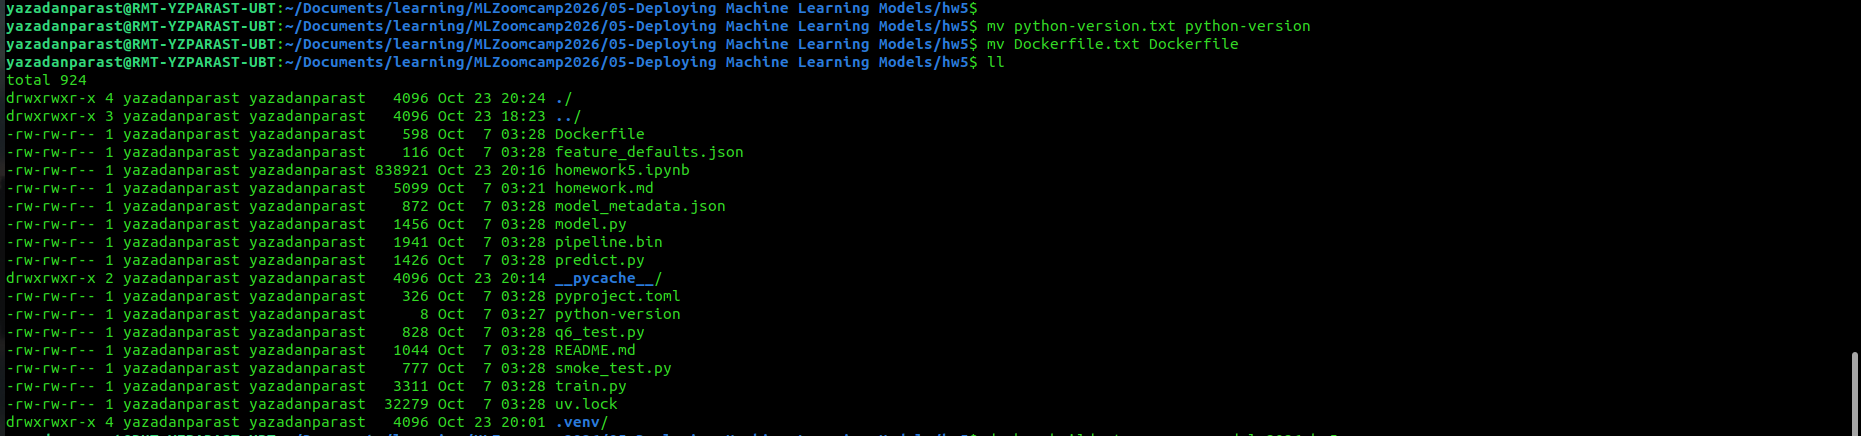

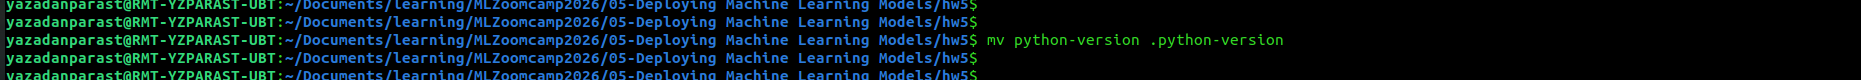

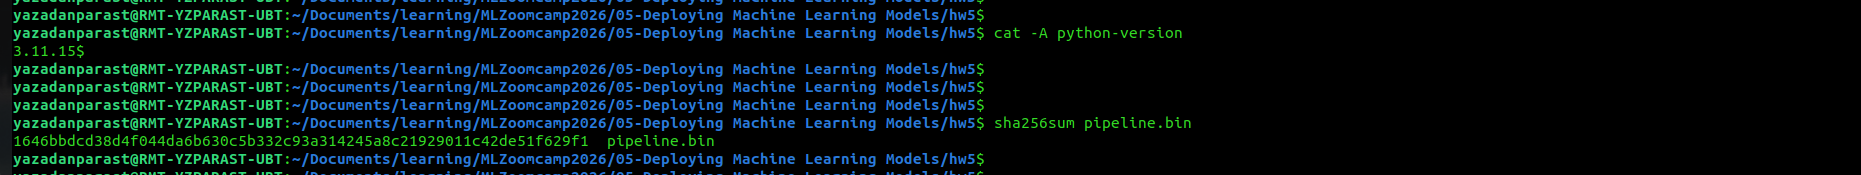

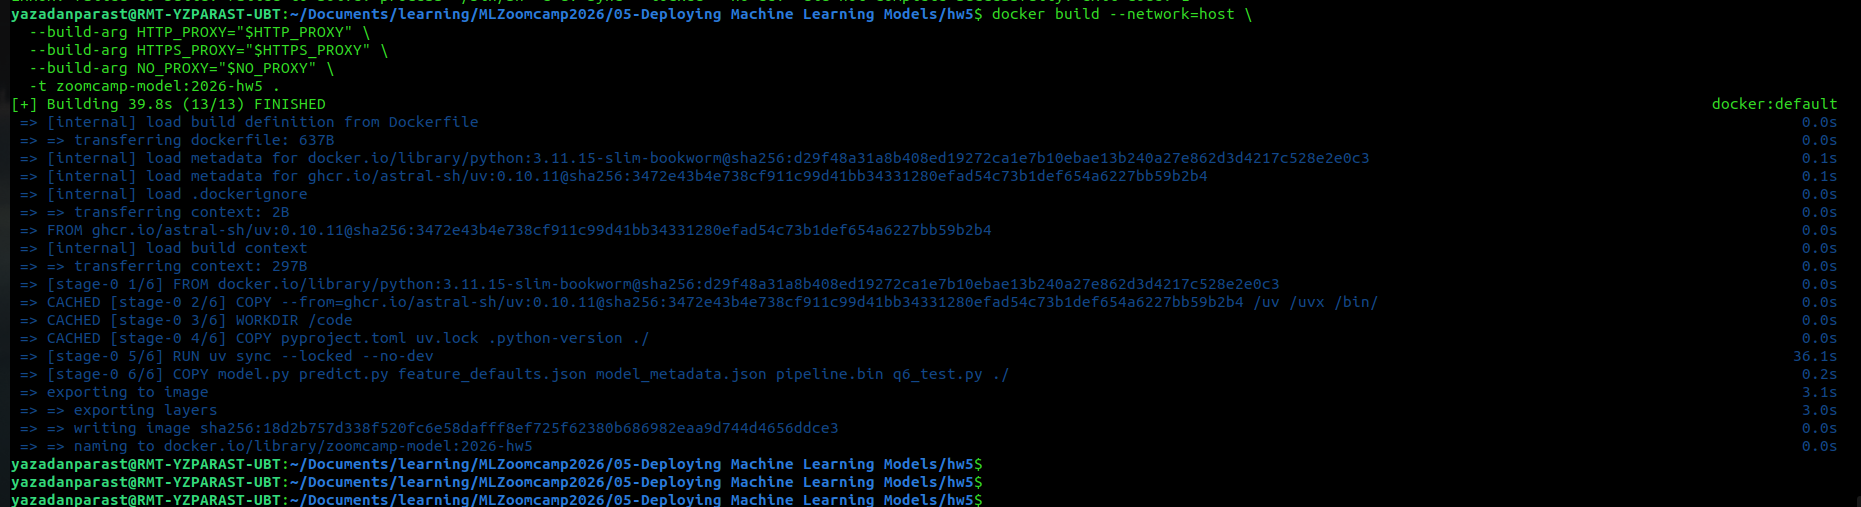

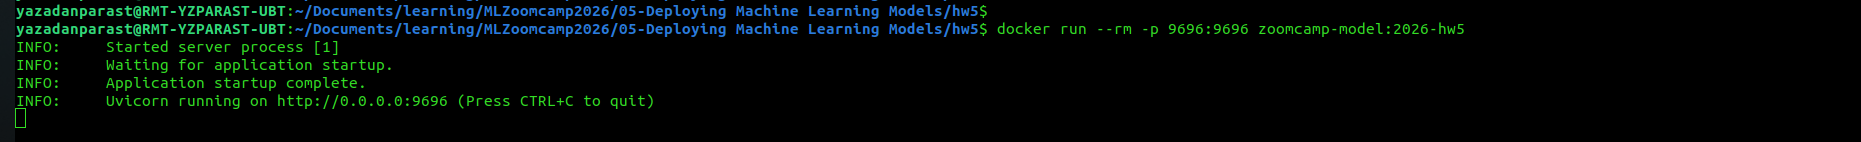

In [10]:
import json
import pickle
from pathlib import Path
from urllib.request import Request, urlopen


# NOTE: `requests` is deliberately NOT used here - it is not in the pinned uv.lock
# (18 packages, no requests). The course's own q6_test.py uses urllib for the same
# reason. Importing requests in this venv raises ModuleNotFoundError.


def post_json(url: str, payload: dict) -> dict:
    """POST a JSON body and return the parsed response."""
    request = Request(
        url,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST",
    )
    with urlopen(request) as response:
        return json.load(response)


def get_json(url: str) -> dict:
    """GET a URL and return the parsed JSON response."""
    with urlopen(url) as response:
        return json.load(response)

In [11]:
# Health check - verify the served model is the frozen artifact

get_json('http://localhost:9696/health')
# {'status': 'ok',
#  'model_sha256': '1646bbdcd38d4f044da6b630c5b332c93a314245a8c21929011c42de51f629f1',
#  'feature_defaults_sha256': '1694f842b908fac9f53c0cc19be6d91f934befc63af23cc32fefafde69acd0cd'}

# model_sha256            == sha256sum pipeline.bin                  OK
# feature_defaults_sha256 == metadata['feature_defaults_sha256']     OK

{'status': 'ok',
 'model_sha256': '1646bbdcd38d4f044da6b630c5b332c93a314245a8c21929011c42de51f629f1',
 'feature_defaults_sha256': '1694f842b908fac9f53c0cc19be6d91f934befc63af23cc32fefafde69acd0cd'}

In [2]:
# Provided smoke client - passes its own assertions on shape and range
!uv run python q6_test.py
# {'conversion_probability': 0.769799, 'conversion': True}

# assert set(result) == {'conversion_probability', 'conversion'}
# assert 0 <= result['conversion_probability'] <= 1
# assert isinstance(result['conversion'], bool)

cpython-3.11.15-linux-x86_64-gnu (download) ------------------------------ 29.49 MiB/29.51 MiB                                                                  Using CPython 3.11.15
Removed virtual environment at: .venv
Creating virtual environment at: .venv
Installed 18 packages in 109ms                              
{'conversion_probability': 0.769799, 'conversion': True}


## Answers
| Q | Question | Answer |
|---|---|---|
| 1 | `uv --version` | setup check — record your own (0.13.4 here) |
| 2 | Locked scikit-learn version | **1.7.2** |
| 3 | Probability, loaded model | **0.533** (raw 0.532994) |
| 4 | Probability, via API | **0.770** (raw 0.769799) |
| 5 | Python base image | **python:3.11.15-slim-bookworm** |
| 6 | Probability, via container | **0.770** (same reference inference as Q4) |

### Verification notes

- `sha256sum pipeline.bin` → `1646bbdc…629f1`, matching the value published in the homework
  and `model_metadata.json["model_sha256"]`.
- `course_lead_scoring_2026.csv` and `feature_defaults.json` also hash to the values recorded in
  `model_metadata.json`, so the whole artifact chain is authentic.
- The reference env was built with `uv sync --locked`, giving Python 3.11.15 + scikit-learn 1.7.2.
- Q3 was re-run under scikit-learn 1.6.1 as well: identical to 3 decimals (0.533), so the answer
  is robust to a slightly stale local environment.
- `/health` returns the model checksum, which is the quickest way to prove the server is running
  the artifact you actually verified.

### One thing worth noticing

`predict.py` loads the model **once at import time** and exposes the checksum through `/health`.
That is the pattern that makes the rest of the homework verifiable: instead of trusting that the
deployed model is the one you trained, you can ask the running service which model it is holding.
In a real deployment that single endpoint is what lets you confirm a rollback actually took
effect.